In [2]:
#REad food texture file

import pandas as pd
import numpy as np

food_texture = pd.read_csv('food-texture.csv')
food_texture.head()

,Unnamed: 0,Oil,Density,Crispy,Fracture,Hardness
0,B110,16.5,2955,10,23,97
1,B136,17.7,2660,14,9,139
2,B171,16.2,2870,12,17,143
3,B192,16.7,2920,10,31,95
4,B225,16.3,2975,11,26,143


In [3]:
def do_eda_bronze(df):
    """
    Perform exploratory data analysis (EDA) on the given DataFrame.
    
    Parameters:
    df (pd.DataFrame): The input DataFrame to analyze.
    
    Returns:
    None
    """
    # Display basic information about the DataFrame
    print("DataFrame Info:")
    print(df.info())
    
    # Display summary statistics for numerical columns
    print("\nSummary Statistics:")
    print(df.describe())
    
    # Check for missing values
    print("\nMissing Values:")
    print(df.isnull().sum())
    
    # Display the first few rows of the DataFrame
    print("\nFirst 5 Rows:")
    print(df.head())

bronze_df = food_texture.copy()
do_eda_bronze(bronze_df)


DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50 non-null     str    
 1   Oil         50 non-null     float64
 2   Density     50 non-null     int64  
 3   Crispy      50 non-null     int64  
 4   Fracture    50 non-null     int64  
 5   Hardness    50 non-null     int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 2.5 KB
None

Summary Statistics:
             Oil     Density     Crispy   Fracture    Hardness
count  50.000000    50.00000  50.000000  50.000000   50.000000
mean   17.202000  2857.60000  11.520000  20.860000  128.180000
std     1.592007   124.49998   1.775571   5.466073   31.127578
min    13.700000  2570.00000   7.000000   9.000000   63.000000
25%    16.300000  2772.50000  10.000000  17.000000  107.250000
50%    16.900000  2867.50000  12.000000  21.000000  126.000000
75%    18.100000  2945.00000  13.000000 

In [4]:
bronze_df.describe()

,Oil,Density,Crispy,Fracture,Hardness
count,50.000000,50.00000,50.000000,50.000000,50.000000
mean,17.202000,2857.60000,11.520000,20.860000,128.180000
std,1.592007,124.49998,1.775571,5.466073,31.127578
min,13.700000,2570.00000,7.000000,9.000000,63.000000
25%,16.300000,2772.50000,10.000000,17.000000,107.250000
50%,16.900000,2867.50000,12.000000,21.000000,126.000000
75%,18.100000,2945.00000,13.000000,25.000000,143.750000
max,21.200000,3125.00000,15.000000,33.000000,192.000000


#### as we can see, the data is clean and ready for analysis. There are no missing values, and the summary statistics provide insights into the distribution of the numerical features.

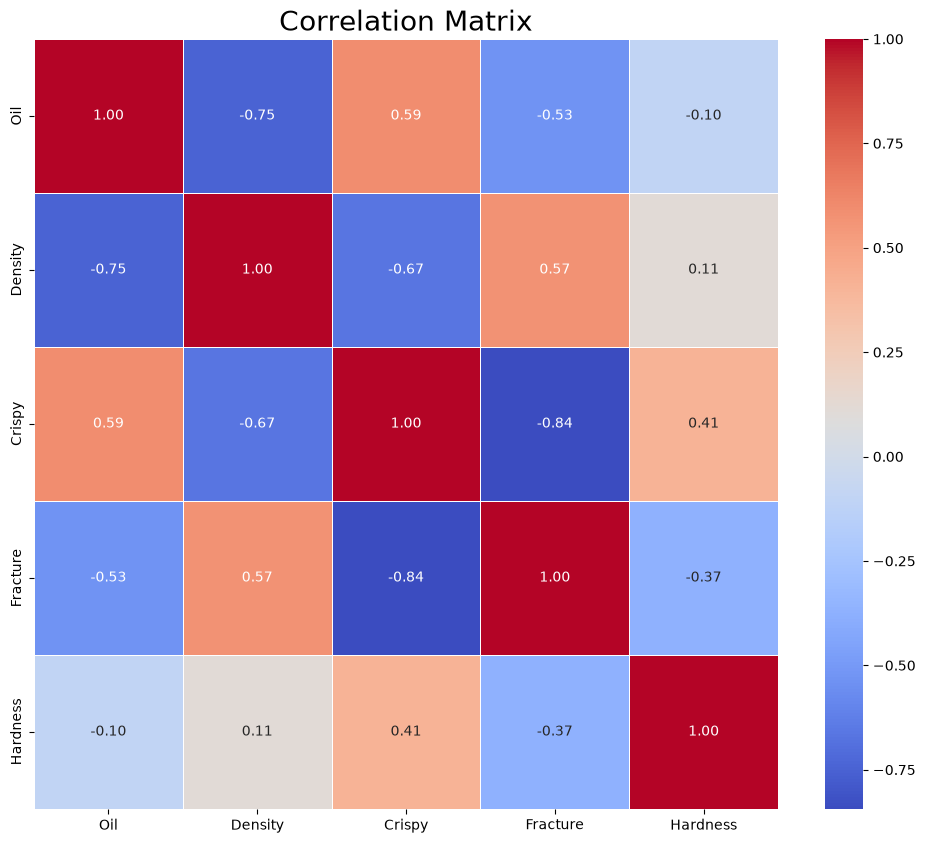

In [5]:
#CORRELATION MATRIX FOR DATASET

import matplotlib.pyplot as plt
import seaborn as sns
df = bronze_df.copy()
df = df.drop(['Unnamed: 0'], axis=1)
plt.figure(figsize=(12, 10))
plt.title('Correlation Matrix', fontsize=20)
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.show()

C:\Users\MSIS\AppData\Local\Temp\ipykernel_27988\2864096139.py:14: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[column], shade=True, color='blue')
C:\Users\MSIS\AppData\Local\Temp\ipykernel_27988\2864096139.py:14: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[column], shade=True, color='blue')
C:\Users\MSIS\AppData\Local\Temp\ipykernel_27988\2864096139.py:14: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[column], shade=True, color='blue')
C:\Users\MSIS\AppData\Local\Temp\ipykernel_27988\2864096139.py:14: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an erro

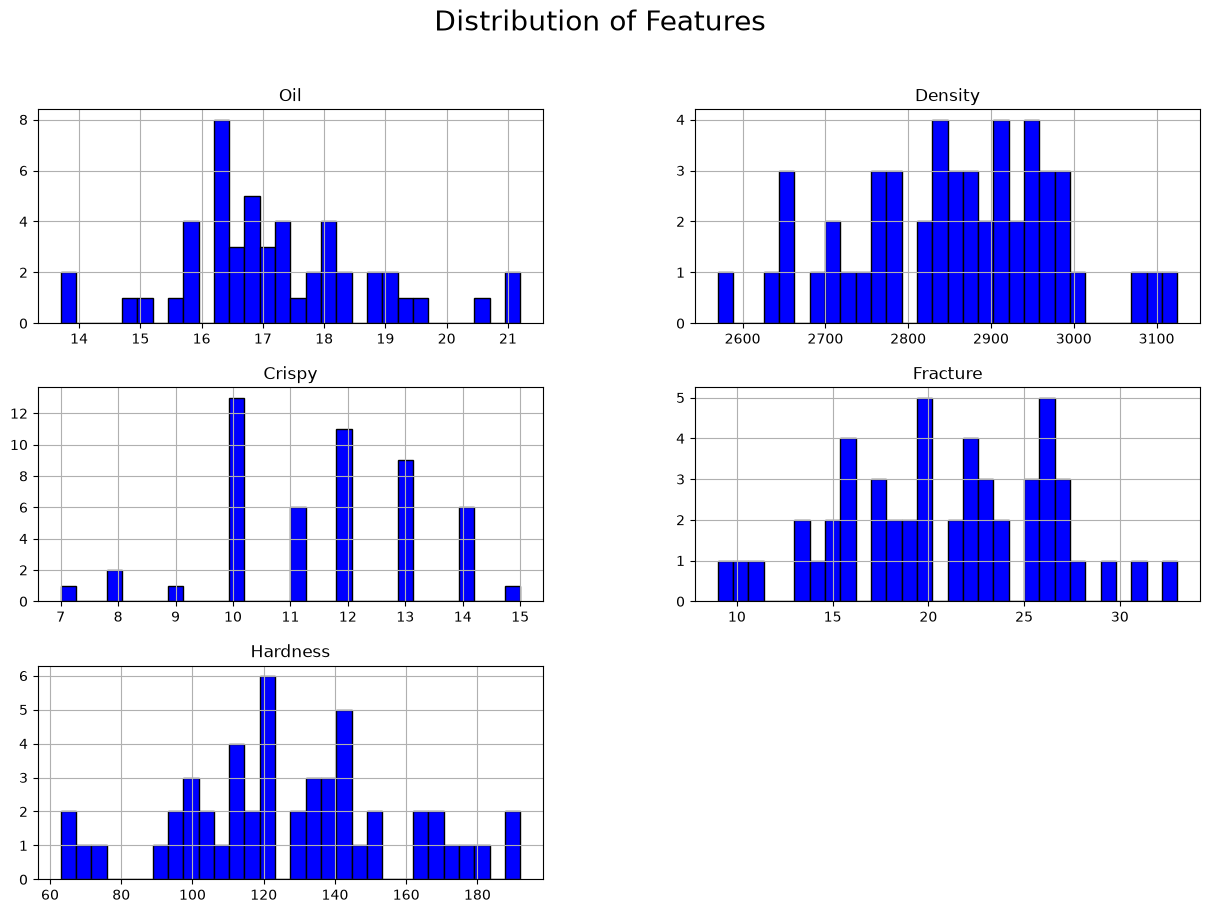

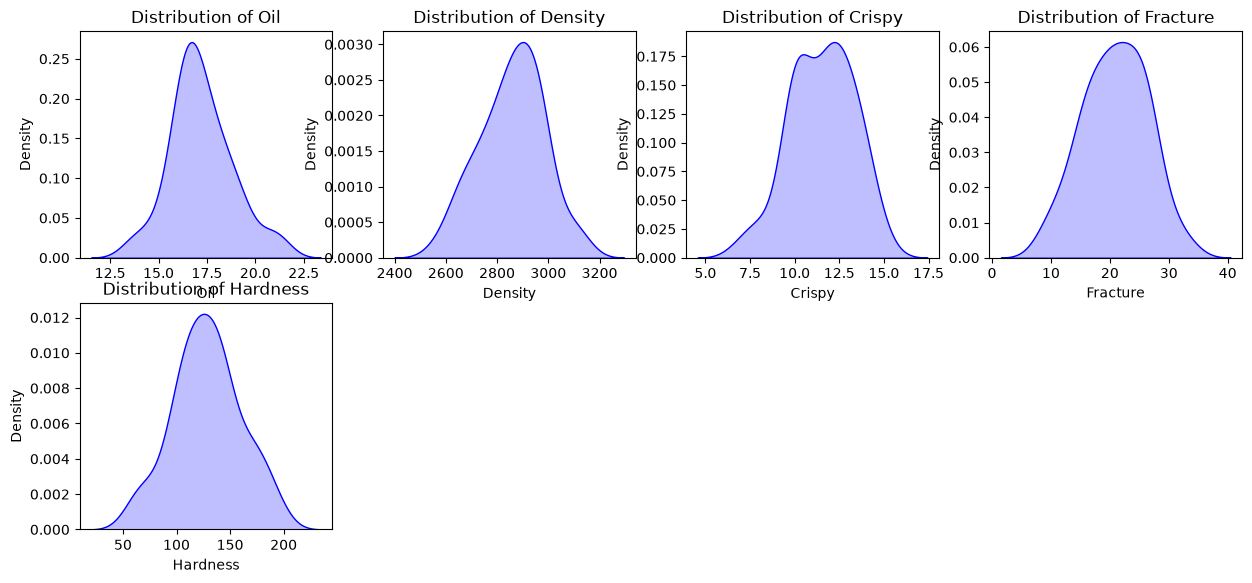

In [6]:
#Distribution plots of each feature in the dataset

import matplotlib.pyplot as plt
import seaborn as sns

df = bronze_df.copy()
df = df.drop(['Unnamed: 0'], axis=1)
df.hist(bins=30, figsize=(15, 10), color='blue', edgecolor='black')
plt.suptitle('Distribution of Features', fontsize=20)
#Standard distribution curves for each feature in the dataset
plt.figure(figsize=(15, 10))
for i, column in enumerate(df.columns):
    plt.subplot(3, 4, i + 1)
    sns.kdeplot(df[column], shade=True, color='blue')
    plt.title(f'Distribution of {column}')
plt.show()

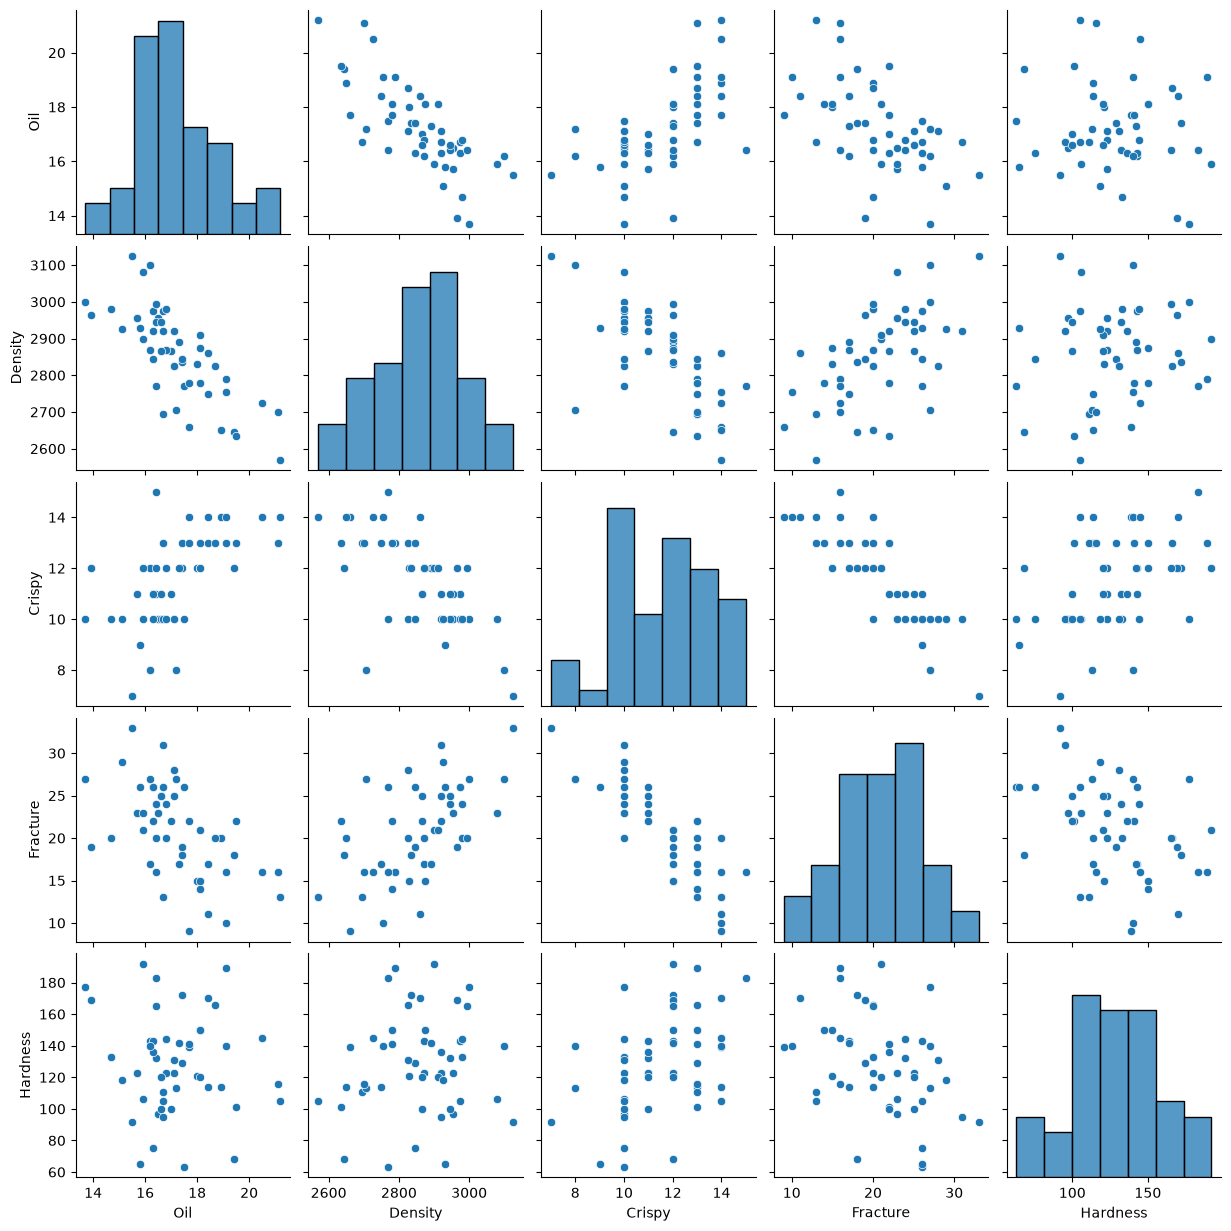

In [7]:
#Create a pairwise scatter plot for each feature in the dataset

df = bronze_df.copy()
df = df.drop(['Unnamed: 0'], axis=1)
sns.pairplot(df)

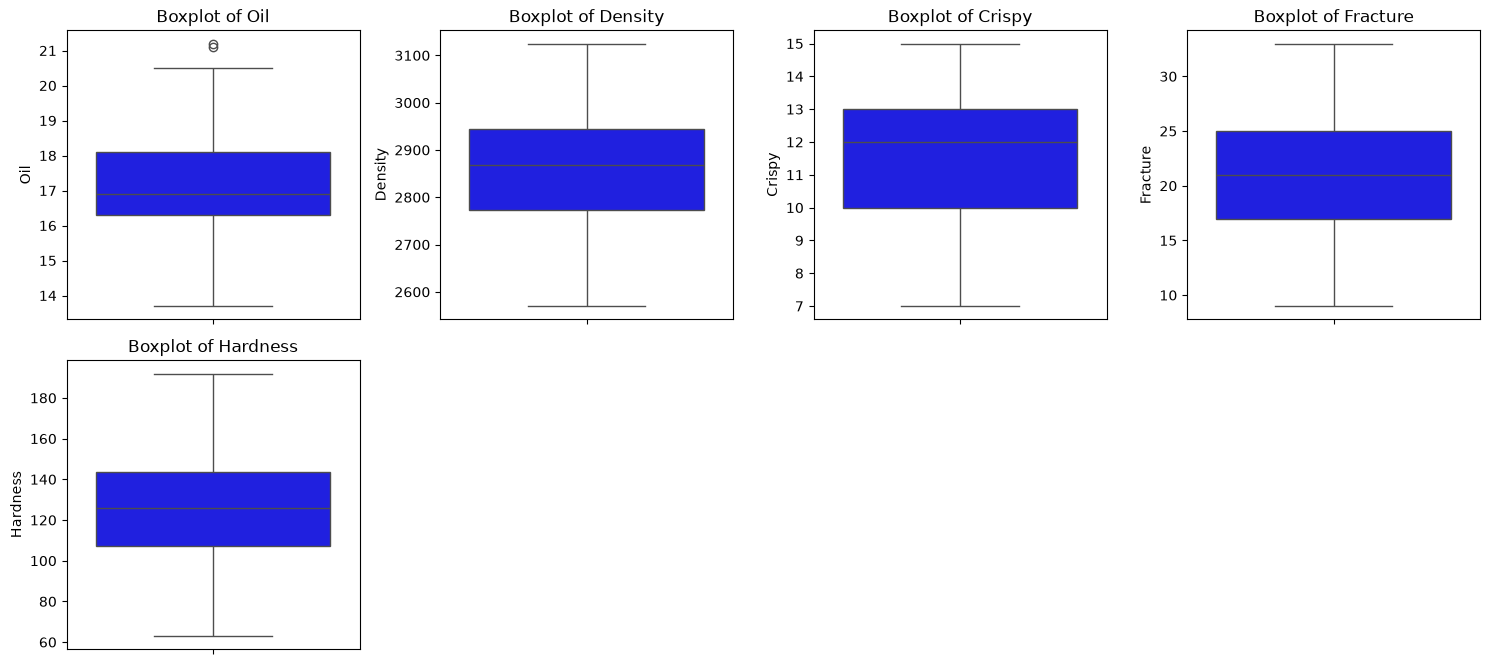

In [8]:
#Create a boxplot for each feature in the dataset to visualize the distribution and identify potential outliers

df = bronze_df.copy()
df = df.drop(['Unnamed: 0'], axis=1)
plt.figure(figsize=(15, 10))
for i, column in enumerate(df.columns):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(y=df[column], color='blue')
    plt.title(f'Boxplot of {column}')
plt.tight_layout()
plt.show()

In [9]:
#Train baseline model using Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier


df = bronze_df.copy()
df = df.drop(['Unnamed: 0'], axis=1)
df = df.dropna()  # Drop rows with missing values
#dependent variable
x = df.drop(['target'], axis=1)
y = df['target']
model = RandomForestClassifier(random_state=42)
model.fit(x, y)
mae = np.mean(np.abs(model.predict(x) - y))
print(f'Mean Absolute Error: {mae}')
mse = np.mean((model.predict(x) - y) ** 2)
print(f'Mean Squared Error: {mse}')
r2 = model.score(x, y)
print(f'R-squared: {r2}')


KeyError: "['target'] not found in axis"

In [ ]:
# Linear Regression baseline for food texture
# Predicting Hardness from the other numerical features

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load data
# Note: Since there is no target column, so we use Hardness as the target here.
df = bronze_df.copy()
df = df.dropna()

X = df[["Oil", "Density", "Crispy", "Fracture"]]
y = df["Hardness"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("R²:", r2_score(y_test, pred))
rmse = mean_squared_error(y_test, pred) ** 0.5
print("RMSE:", rmse)
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)


R²: 0.3706592283128267
RMSE: 18.850087524851922
Coefficients: [-3.01644073  0.171271   13.44840711 -0.80524444]
Intercept: -445.20179633167936
